# TRUSTSR Lab 01.8 — Threshold Sensitivity and Stress Testing

**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0  
**Builds on:** Lab 01.7 — Blind Missing-Dependency Detection

## Why this lab comes next
Lab 01.7 evaluated a blind degree-deficit heuristic across 300 synthetic trials. Its mean false-negative rate was about 0.0051, versus 0.1885 for observed reachability, but the heuristic quarantined more states on average. Those findings depend on a strong assumption: the detector receives expected in-degree metadata, with 10% controlled noise. They do not establish real-world effectiveness.

This lab asks: **How sensitive are the results to the heuristic threshold, missing-edge rate, and metadata noise?**

## Policies
- **Observed reachability:** quarantine observed descendants of the poison source.
- **Blind degree-deficit heuristic:** observed reachability plus suspicious nodes whose deficit `max(0, expected_in_degree - observed_in_degree)` meets a threshold; quarantine their observed descendants.
- **Oracle reference:** sees exact removed-edge identities. This is a non-deployable reference only.

## Experiment plan
Run a parameter grid across:
- deficit threshold: 1, 2, 3
- missing-edge probability: 0.05, 0.15, 0.30
- expected-degree metadata noise: 0.00, 0.10, 0.30

Use a fixed seed, randomized synthetic DAGs, and 100 trials per parameter combination. Record false-negative rate and quarantine overhead. All results are synthetic; they must not be described as evidence from real agent systems.

## 1. Install and configure

In [1]:
%pip -q install networkx pandas numpy matplotlib

In [2]:
import sys, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

SEED = 20261012
N_TRIALS_PER_CELL = 100
N_NODES = 24
EDGE_PROBABILITY = 0.13
THRESHOLDS = [1, 2, 3]
MISSING_EDGE_RATES = [0.05, 0.15, 0.30]
METADATA_NOISE_RATES = [0.00, 0.10, 0.30]
rng = np.random.default_rng(SEED)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__, "| Pandas:", pd.__version__, "| NumPy:", np.__version__)
print("Seed:", SEED)
print("Trials per parameter cell:", N_TRIALS_PER_CELL)
print("Parameter cells:", len(THRESHOLDS) * len(MISSING_EDGE_RATES) * len(METADATA_NOISE_RATES))
print("Maximum planned trials:", N_TRIALS_PER_CELL * len(THRESHOLDS) * len(MISSING_EDGE_RATES) * len(METADATA_NOISE_RATES))
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1 | Pandas: 3.0.2 | NumPy: 2.4.4
Seed: 20261012
Trials per parameter cell: 100
Parameter cells: 27
Maximum planned trials: 2700
Execution UTC: 2026-10-11T10:26:28.030652+00:00
Evidence type: synthetic simulation only


## 2. Define graph and policy functions

In [3]:
def generate_graph(rng, n_nodes=N_NODES, edge_p=EDGE_PROBABILITY):
    G = nx.DiGraph()
    G.add_nodes_from(range(n_nodes))
    for u in range(n_nodes):
        for v in range(u + 1, n_nodes):
            if rng.random() < edge_p:
                G.add_edge(u, v)
    if G.out_degree(0) == 0:
        G.add_edge(0, int(rng.integers(1, n_nodes)))
    return G

def hide_edges(G_truth, rng, removal_p):
    G_obs = G_truth.copy()
    removed = []
    for edge in list(G_truth.edges()):
        if rng.random() < removal_p:
            G_obs.remove_edge(*edge)
            removed.append(edge)
    return G_obs, removed

def descendants_union(G, nodes):
    result = set(nodes)
    for node in list(nodes):
        result.update(nx.descendants(G, node))
    return result

def make_degree_metadata(G_truth, rng, noise_rate):
    metadata = {}
    for node in G_truth.nodes():
        count = G_truth.in_degree(node)
        if rng.random() < noise_rate:
            count = max(0, count + int(rng.choice([-1, 1])))
        metadata[node] = count
    return metadata

def baseline_quarantine(G_obs, source=0):
    return set(nx.descendants(G_obs, source))

def heuristic_quarantine(G_obs, expected_in_degree, threshold, source=0):
    base = baseline_quarantine(G_obs, source)
    deficit = {
        node: max(0, expected_in_degree[node] - G_obs.in_degree(node))
        for node in G_obs.nodes()
    }
    flagged = {node for node, d in deficit.items() if node != source and d >= threshold}
    q = base | descendants_union(G_obs, flagged)
    q.discard(source)
    return q, flagged

def oracle_quarantine(G_obs, removed_edges, source=0):
    # Non-deployable reference: it receives the true missing-edge identities.
    q = baseline_quarantine(G_obs, source)
    endpoints = {v for _, v in removed_edges}
    q |= descendants_union(G_obs, endpoints)
    q.discard(source)
    return q

print("Functions defined.")

Functions defined.


## 3. Run the parameter sweep

In [4]:
rows = []
trial_id = 0
for missing_rate in MISSING_EDGE_RATES:
    for noise_rate in METADATA_NOISE_RATES:
        for threshold in THRESHOLDS:
            for rep in range(N_TRIALS_PER_CELL):
                G_truth = generate_graph(rng)
                G_obs, removed = hide_edges(G_truth, rng, missing_rate)
                affected = set(nx.descendants(G_truth, 0))
                if not affected:
                    continue
                unaffected = set(G_truth.nodes()) - affected - {0}
                metadata = make_degree_metadata(G_truth, rng, noise_rate)

                policies = [
                    ("Observed reachability", baseline_quarantine(G_obs), 0),
                    ("Blind degree-deficit heuristic", *heuristic_quarantine(
                        G_obs, metadata, threshold, source=0
                    )[:1], 0),
                ]
                # Build the heuristic result explicitly to avoid ambiguity in tuple unpacking.
                q_heuristic, flagged = heuristic_quarantine(G_obs, metadata, threshold, source=0)
                q_baseline = baseline_quarantine(G_obs)
                q_oracle = oracle_quarantine(G_obs, removed)

                for policy, quarantine, flagged_count in [
                    ("Observed reachability", q_baseline, 0),
                    ("Blind degree-deficit heuristic", q_heuristic, len(flagged)),
                    ("Oracle reference (not deployable)", q_oracle, len({v for _, v in removed})),
                ]:
                    missed = affected - quarantine
                    over = unaffected & quarantine
                    rows.append({
                        "trial_id": trial_id,
                        "replicate": rep,
                        "threshold": threshold,
                        "missing_edge_rate": missing_rate,
                        "metadata_noise_rate": noise_rate,
                        "strategy": policy,
                        "affected_count": len(affected),
                        "false_negative_count": len(missed),
                        "false_negative_rate": len(missed) / len(affected),
                        "quarantined_count": len(quarantine),
                        "over_quarantined_unaffected_count": len(over),
                        "unaffected_preservation_rate": len(unaffected - quarantine) / len(unaffected) if unaffected else np.nan,
                        "missing_edge_count": len(removed),
                        "flagged_node_count": flagged_count,
                    })
                trial_id += 1

results_df = pd.DataFrame(rows)
print("Executed graph trials:", results_df["trial_id"].nunique())
print("Strategy-result rows:", len(results_df))
print("Planned graph trials:", N_TRIALS_PER_CELL * len(THRESHOLDS) * len(MISSING_EDGE_RATES) * len(METADATA_NOISE_RATES))
display(results_df.head())

Executed graph trials: 2700
Strategy-result rows: 8100
Planned graph trials: 2700


   trial_id  replicate  threshold  missing_edge_rate  metadata_noise_rate                           strategy  affected_count  false_negative_count  false_negative_rate  quarantined_count  \
0         0          0          1               0.05                  0.0              Observed reachability               4                     0             0.000000                  4   
1         0          0          1               0.05                  0.0     Blind degree-deficit heuristic               4                     0             0.000000                 11   
2         0          0          1               0.05                  0.0  Oracle reference (not deployable)               4                     0             0.000000                 11   
3         1          1          1               0.05                  0.0              Observed reachability              12                     1             0.083333                 11   
4         1          1          1               0.

## 4. Aggregate results by parameter combination

In [5]:
summary = results_df.groupby(
    ["threshold", "missing_edge_rate", "metadata_noise_rate", "strategy"], as_index=False
).agg(
    trial_rows=("trial_id", "count"),
    mean_false_negative_rate=("false_negative_rate", "mean"),
    median_false_negative_rate=("false_negative_rate", "median"),
    mean_quarantined_count=("quarantined_count", "mean"),
    mean_over_quarantined_unaffected=("over_quarantined_unaffected_count", "mean"),
    mean_unaffected_preservation_rate=("unaffected_preservation_rate", "mean"),
    mean_flagged_node_count=("flagged_node_count", "mean"),
)
display(summary.head(18))
print("All aggregate values describe this parameterized synthetic simulation only.")

    threshold  missing_edge_rate  metadata_noise_rate                           strategy  trial_rows  mean_false_negative_rate  median_false_negative_rate  mean_quarantined_count  \
0           1               0.05                  0.0     Blind degree-deficit heuristic         100                  0.000000                    0.000000                    9.63   
1           1               0.05                  0.0              Observed reachability         100                  0.088309                    0.000000                    7.85   
2           1               0.05                  0.0  Oracle reference (not deployable)         100                  0.000000                    0.000000                    9.63   
3           1               0.05                  0.1     Blind degree-deficit heuristic         100                  0.003636                    0.000000                   11.30   
4           1               0.05                  0.1              Observed reachability  

All aggregate values describe this parameterized synthetic simulation only.


## 5. Plot heuristic sensitivity to threshold

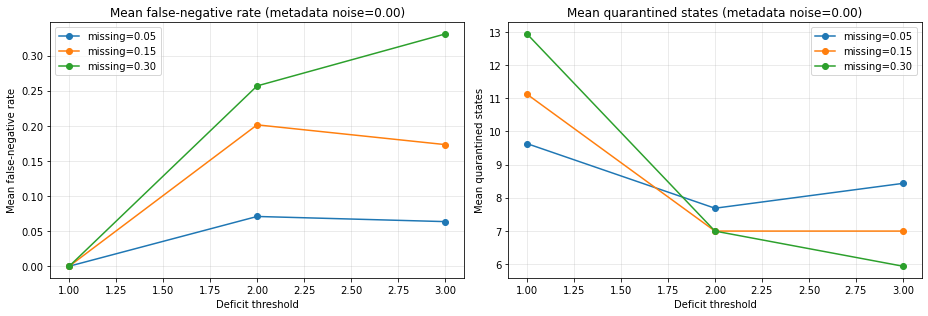

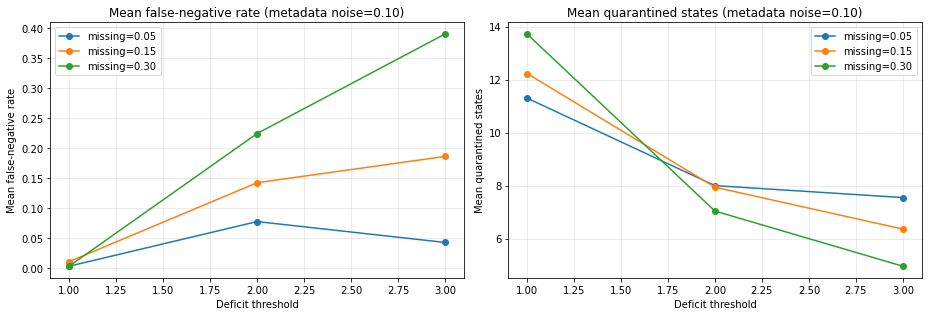

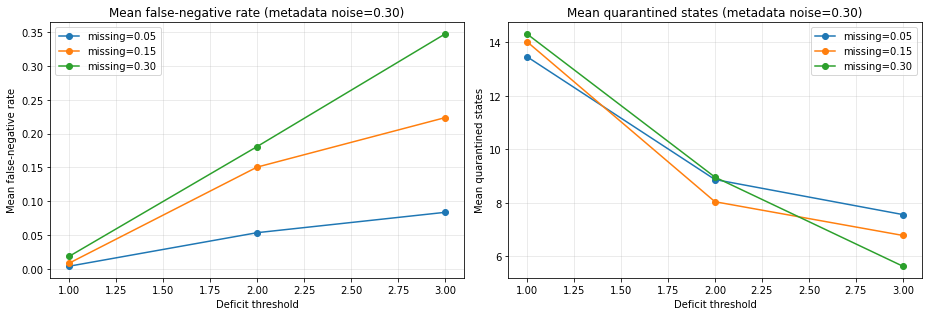

In [6]:
heur = summary[summary["strategy"] == "Blind degree-deficit heuristic"]
for noise_rate in METADATA_NOISE_RATES:
    subset = heur[heur["metadata_noise_rate"] == noise_rate]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for missing_rate in MISSING_EDGE_RATES:
        s = subset[subset["missing_edge_rate"] == missing_rate].sort_values("threshold")
        axes[0].plot(s["threshold"], s["mean_false_negative_rate"], marker="o", label=f"missing={missing_rate:.2f}")
        axes[1].plot(s["threshold"], s["mean_quarantined_count"], marker="o", label=f"missing={missing_rate:.2f}")
    axes[0].set_title(f"Mean false-negative rate (metadata noise={noise_rate:.2f})")
    axes[0].set_xlabel("Deficit threshold")
    axes[0].set_ylabel("Mean false-negative rate")
    axes[1].set_title(f"Mean quarantined states (metadata noise={noise_rate:.2f})")
    axes[1].set_xlabel("Deficit threshold")
    axes[1].set_ylabel("Mean quarantined states")
    for ax in axes:
        ax.legend()
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 6. Compare methods at each missing-edge rate

strategy           Blind degree-deficit heuristic  Observed reachability  Oracle reference (not deployable)
missing_edge_rate                                                                                          
0.05                                     0.003636               0.061930                                0.0
0.15                                     0.011269               0.172318                                0.0
0.30                                     0.003789               0.362732                                0.0

strategy           Blind degree-deficit heuristic  Observed reachability  Oracle reference (not deployable)
missing_edge_rate                                                                                          
0.05                                        11.30                   8.36                              10.12
0.15                                        12.23                   6.95                              11.24
0.30                                        13.72                   5.58                              12.97

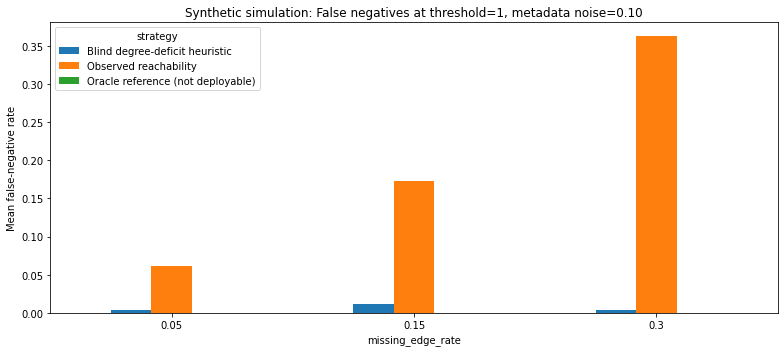

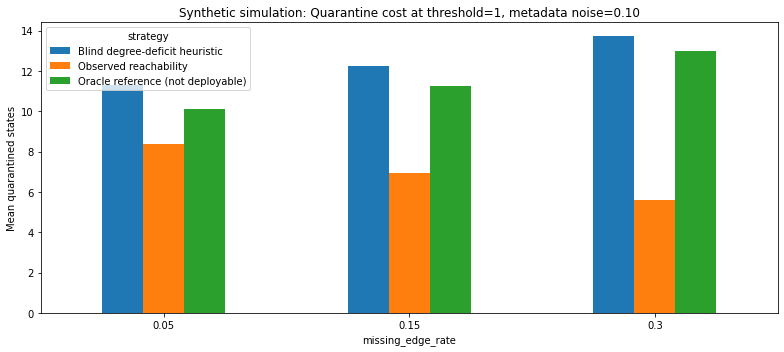

In [7]:
fixed = summary[
    (summary["threshold"] == 1) &
    (summary["metadata_noise_rate"] == 0.10)
]
for metric, ylabel, title in [
    ("mean_false_negative_rate", "Mean false-negative rate", "False negatives at threshold=1, metadata noise=0.10"),
    ("mean_quarantined_count", "Mean quarantined states", "Quarantine cost at threshold=1, metadata noise=0.10"),
]:
    pivot = fixed.pivot(index="missing_edge_rate", columns="strategy", values=metric)
    ax = pivot.plot(kind="bar", figsize=(11, 5))
    ax.set_ylabel(ylabel)
    ax.set_title("Synthetic simulation: " + title)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    display(pivot)

## 7. Assertions

In [8]:
assert not results_df.empty
assert results_df["false_negative_rate"].between(0, 1).all()
assert results_df["unaffected_preservation_rate"].dropna().between(0, 1).all()
assert results_df["false_negative_count"].ge(0).all()
assert results_df["quarantined_count"].ge(0).all()
assert set(results_df["threshold"].unique()) == set(THRESHOLDS)
assert set(results_df["missing_edge_rate"].unique()) == set(MISSING_EDGE_RATES)
assert set(results_df["metadata_noise_rate"].unique()) == set(METADATA_NOISE_RATES)
assert set(results_df["strategy"].unique()) == {
    "Observed reachability",
    "Blind degree-deficit heuristic",
    "Oracle reference (not deployable)",
}
wide = results_df.pivot_table(
    index=["trial_id", "threshold", "missing_edge_rate", "metadata_noise_rate"],
    columns="strategy", values="quarantined_count"
)
assert (wide["Blind degree-deficit heuristic"] >= wide["Observed reachability"]).all()
assert (wide["Oracle reference (not deployable)"] >= wide["Observed reachability"]).all()
print("PASS: parameter grid contains all configured values.")
print("PASS: rates and counts are within valid bounds.")
print("PASS: heuristic and oracle quarantines include baseline reachability.")
print("PASS: oracle remains explicitly marked as non-deployable.")
print("All Lab 01.8 assertions passed.")

PASS: parameter grid contains all configured values.
PASS: rates and counts are within valid bounds.
PASS: heuristic and oracle quarantines include baseline reachability.
PASS: oracle remains explicitly marked as non-deployable.
All Lab 01.8 assertions passed.


## 8. Export CSV artifacts

In [9]:
results_df.to_csv("trustsr_lab01_8_sensitivity_trial_results.csv", index=False)
summary.to_csv("trustsr_lab01_8_sensitivity_summary.csv", index=False)
heur.to_csv("trustsr_lab01_8_heuristic_sensitivity_only.csv", index=False)
print("Generated files:")
print("- trustsr_lab01_8_sensitivity_trial_results.csv")
print("- trustsr_lab01_8_sensitivity_summary.csv")
print("- trustsr_lab01_8_heuristic_sensitivity_only.csv")

Generated files:
- trustsr_lab01_8_sensitivity_trial_results.csv
- trustsr_lab01_8_sensitivity_summary.csv
- trustsr_lab01_8_heuristic_sensitivity_only.csv


## 9. Interpretation and publication limitations

1. **Synthetic simulation only.** No real agent memory, logs, or production dependencies are evaluated.
2. **Metadata assumption remains strong.** The heuristic receives expected in-degree counts derived from the ground-truth graph and perturbed with controlled noise. This is a benchmark convenience, not a real detector input guarantee.
3. **Oracle reference is not deployable.** It uses the actual removed-edge list.
4. **Graph topology is simplified.** The generator creates DAGs by node order; real systems can have temporal state, cycles, external side effects, and unobserved dependencies.
5. **Metrics do not prove recovery.** Quarantine-set scoring does not implement checkpoint restoration, credential rotation, or compensation of external actions.
6. **Do not cherry-pick.** Report the full parameter grid, including unfavorable cells, not only the best threshold.
7. **No unsupported superiority claim.** Conclude only what the measured synthetic outcomes support under these explicit assumptions.

Recommended next research step after this lab: replace the synthetic expected-degree oracle with a detector based only on observable event logs, then evaluate on held-out synthetic scenarios before attempting real-agent integration.